In [2]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

## Part c

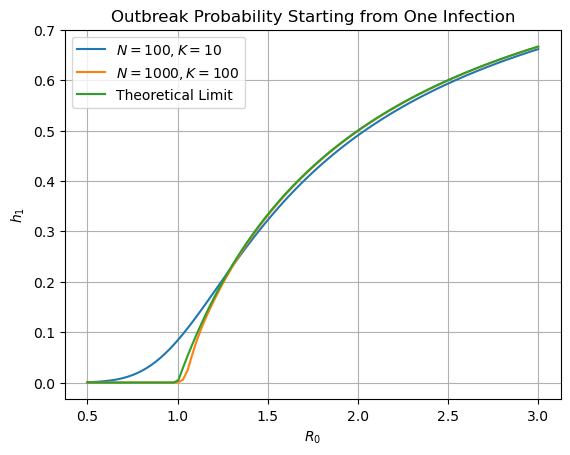

In [ ]:
N = 100
K = N/10
# to make the smooth curve and not just disjointed points
R0_vec = np.linspace(0.5, 3.0, 100)
h1_vec = []
k_vals = np.arange(1, K)

# use the given formula to calculate the stuff
def calc_h_new(h1_vec, R0, k_vals, N):
    vals = N/(R0*(N-k_vals))
    # to save the successive rho's and then sum them back up but don't forget rho0 = 1 so need to include that
    rho = np.cumprod(vals)
    rho = np.concatenate(([1], rho))
    h1_vec.append(1/(np.sum(rho)))

for r in R0_vec:
    calc_h_new(h1_vec, r, k_vals, N)

# do it again for N = 1000 now 
N2 = 1000
K2 = N2/10
h12_vec = []
k2_vals = np.arange(1, K2)
for r in R0_vec:
    calc_h_new(h12_vec, r, k2_vals, N2)

# 1 - 1/r0
h1_lim = np.maximum(0, 1-1/R0_vec)

plt.plot(R0_vec, h1_vec, label='$N=100, K=10$')
plt.plot(R0_vec, h12_vec, label='$N=1000, K=100$')
plt.plot(R0_vec, h1_lim, label='Theoretical Limit')
plt.xlabel('$R_0$')
plt.ylabel('$h_1$')
plt.title('Outbreak Probability Starting from One Infection')
plt.grid()
plt.legend()

# dont mind me doing the completely wrong thing - but i'm not going to delete it because i tried

# k_vals = np.arange(1, K)
# vals1 = N/(R01*(N-k_vals))
# rho1 = np.cumprod(vals1)
# rho1 = np.concatenate(([1], rho1))
# h11 = 1/(np.sum(rho1))

# vals2 = N/(R02*(N-k_vals))
# rho2 = np.cumprod(vals2)
# rho2 = np.concatenate(([1], rho2))
# h12 = 1/(np.sum(rho2))

# vals3 = N/(R03*(N-k_vals))
# rho3 = np.cumprod(vals3)
# rho3 = np.concatenate(([1], rho3))
# h13 = 1/(np.sum(rho3))

# vals4 = N/(R04*(N-k_vals))
# rho4 = np.cumprod(vals4)
# rho4 = np.concatenate(([1], rho4))
# h14 = 1/(np.sum(rho4))

# vals5 = N/(R05*(N-k_vals))
# rho5 = np.cumprod(vals5)
# rho5 = np.concatenate(([1], rho5))
# h15 = 1/(np.sum(rho5))


## Part d

In [ ]:
# back to N=100
N = 100
K = 10
gamma = 1
delT = 0.005


p = np.zeros((4, K-1))
q = np.zeros((4, K-1))
R0_vec = [0.5, 0.8, 1.5, 3.0]
# yes I know there is a better way to do this but I can't think of it right now
beta = [R0_vec[0]/100, R0_vec[1]/100, R0_vec[2]/100, R0_vec[3]/100]
n = np.arange(1, K)
for i in range(4):
    for j in n:
        # set up all the stuff but because n starts at 1 we gotta go back to make sure it goes from 0 -> K-1
        p[i,j-1] = beta[i] * j * (N-j) * delT
        q[i,j-1] = gamma * j * delT

# once again, 0 -> K-1 (so only 9 entries) - could generalize it - don't care
b = np.ones(9)

# diagonal elements to put in because this time I'm not building a 10x10 matrix line by line
diag1 = p[0, :] + q[0, :]
upper1 = -p[0,:-1]
lower1 = -q[0, 1:]
A1 = np.diag(diag1, k=0) + np.diag(upper1, k=1) + np.diag(lower1, k=-1)

# especially for 4 different r0 values
diag2 = p[1, :] + q[1, :]
upper2 = -p[1,:-1]
lower2 = -q[1, 1:]
A2 = np.diag(diag2, k=0) + np.diag(upper2, k=1) + np.diag(lower2, k=-1)

# so many lines - I bet there was a more efficient way for this too
diag3 = p[2, :] + q[2, :]
upper3 = -p[2,:-1]
lower3 = -q[2, 1:]
A3 = np.diag(diag3, k=0) + np.diag(upper3, k=1) + np.diag(lower3, k=-1)

# last one
diag4 = p[3, :] + q[3, :]
upper4 = -p[3,:-1]
lower4 = -q[3, 1:]
A4 = np.diag(diag4, k=0) + np.diag(upper4, k=1) + np.diag(lower4, k=-1)

# solve them get what we want, and print it
e1 = np.linalg.solve(A1, b)
e1t = e1 * delT
e2 = np.linalg.solve(A2, b)
e2t = e2 * delT
e3 = np.linalg.solve(A3, b)
e3t = e3 * delT
e4 = np.linalg.solve(A4, b)
e4t = e4 * delT

print('R0 = 0.5:')
print(f'    e1    = {e1[0]:.4f}')
print(f'e1 * delT = {e1t[0]:.4f}')
print('R0 = 0.8:')
print(f'    e1    = {e2[0]:.4f}')
print(f'e1 * delT = {e2t[0]:.4f}')
print('R0 = 1.5:')
print(f'    e1    = {e3[0]:.4f}')
print(f'e1 * delT = {e3t[0]:.4f}')
print('R0 = 3.0:')
print(f'    e1    = {e4[0]:.4f}')
print(f'e1 * delT = {e4t[0]:.4f}')


R0 = 0.5:
    e1    = 274.7149
e1 * delT = 1.3736
R0 = 0.8:
    e1    = 353.9752
e1 * delT = 1.7699
R0 = 1.5:
    e1    = 359.1705
e1 * delT = 1.7959
R0 = 3.0:
    e1    = 193.0973
e1 * delT = 0.9655


In [ ]:
# check by simulation 
N = 100
K = 10
gamma = 1
delT = 0.005
r0 = 1.5 # as an example just to check
beta = (r0 * gamma) / N

n_sims = 5000
times = []

for _ in range(n_sims):
    # n is count of infected
    n = 1
    steps = 0
    while 0 < n < K:
        pn = beta * n * (N-n) * delT
        qn = gamma * n * delT

        r = np.random.uniform(0, 1)
        # wow it's the sampling again
        if r < pn:
            n += 1
        elif r < (pn+qn):
            n -= 1

        steps += 1
    # once we hit n=K, track the time
    times.append(steps * delT)

# take the average - maybe could take out the first so many steps to get more accurate but it's pretty close
e1delT = np.mean(times)
print(e1delT)

1.7694
